# **Projek Akhir Data Warehouse - Outcome Pasien**

**Import Library**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import sqlite3
import os
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams['figure.facecolor'] = '#F8F9FA'
plt.rcParams['axes.facecolor']   = '#F0F4F8'
plt.rcParams['font.family']      = 'DejaVu Sans'

## **Extract**

In [ ]:
df_healthcare = pd.read_csv(r"D:\Semester 4\Data Warehouse\Projek Akhir Data Warehouse\Healthcare Data Analysis for readmission.csv")
df_patients     = pd.read_csv(r"D:\Semester 4\Data Warehouse\Projek Akhir Data Warehouse\patients.csv")
df_doctors      = pd.read_csv(r"D:\Semester 4\Data Warehouse\Projek Akhir Data Warehouse\doctors.csv")
df_appointments = pd.read_csv(r"D:\Semester 4\Data Warehouse\Projek Akhir Data Warehouse\appointments.csv")
df_treatments   = pd.read_csv(r"D:\Semester 4\Data Warehouse\Projek Akhir Data Warehouse\treatments.csv")
df_billing      = pd.read_csv(r"D:\Semester 4\Data Warehouse\Projek Akhir Data Warehouse\billing.csv")

sources = {
    "DS1 | Healthcare Readmission": df_healthcare,
    "DS2 | patients"              : df_patients,
    "DS2 | doctors"               : df_doctors,
    "DS2 | appointments"          : df_appointments,
    "DS2 | treatments"            : df_treatments,
    "DS2 | billing"               : df_billing,
}
for name, df in sources.items():
    print(f"  {name:<35} : {df.shape[0]:>5} baris, {df.shape[1]:>2} kolom")

  DS1 | Healthcare Readmission        : 10000 baris, 26 kolom
  DS2 | patients                      :    50 baris, 11 kolom
  DS2 | doctors                       :    10 baris,  8 kolom
  DS2 | appointments                  :   200 baris,  7 kolom
  DS2 | treatments                    :   200 baris,  6 kolom
  DS2 | billing                       :   200 baris,  7 kolom


**Preview Dataset 1 - Healthcare Readmission**

In [7]:
df_healthcare.head()

,hospital_name,Admission_date,hospital_id,hospital_beds_available,occupied_beds,hospital_ward,patient_id,patient_gender,patient_age,patient_race,patient_sat_score,patient_first_initial,patient_last_name,patient_waittime,department_referral,time_slot,doctor_id,doctor_name,doctor_specialty,patient_assigned_doctor,patient_checkin_date,patient_checkout_date,patient_disease,patient_length_of_stay,discharge_status,readmission
0,The Johns Hopkins Hospital,30-01-2024,3946,260,90,Maternity,1421,Female,48,Asian,490,t,Rogers,120,Urology or Nephrology,02:34:00 PM,1725,Justin Morris,Rheumatology,False,14-07-2024,19-07-2024,Anxiety Disorders,6,Deceased,1
1,The Johns Hopkins Hospital,20-03-2022,7147,250,90,ICU,4922,Male,40,Black,1210,i,Spencer,60,Neurology,04:07:00 PM,7510,Latoya Moss,Pulmonology or Allergy and Immunology,False,19-07-2024,07/07/2024,Urinary Tract Infection (UTI),2,Deceased,1
2,The Johns Hopkins Hospital,13-07-2021,4174,350,220,Pediatrics,9804,Female,74,Black,920,Y,Hall,120,Neurology,07:16:00 PM,7137,Michael Allen,Neurology,False,20-07-2024,29-06-2024,Hypertension (High Blood Pressure),17,Recovered,0
3,The Johns Hopkins Hospital,26-01-2021,2466,190,350,Pediatrics,5622,Male,82,Hispanic,1010,s,Rodriguez,75,Gastroenterology,07:27:00 AM,8801,Rebecca Mccullough,Cardiology,False,25-06-2024,16-07-2024,Arthritis,28,Recovered,0
4,The Johns Hopkins Hospital,06/02/2024,3014,220,390,Surgery,3314,Male,62,Hispanic,570,o,Duffy,90,Dermatology,01:54:00 PM,3588,John Giles,Rheumatology,False,21-07-2024,19-07-2024,Cancer,16,Transferred,1


**Preview Dataset 2 - Patients**

In [8]:
df_patients.head()


,patient_id,first_name,last_name,gender,date_of_birth,contact_number,address,registration_date,insurance_provider,insurance_number,email
0,P001,David,Williams,F,1955-06-04,6939585183,789 Pine Rd,2022-06-23,WellnessCorp,INS840674,david.williams@mail.com
1,P002,Emily,Smith,F,1984-10-12,8228188767,321 Maple Dr,2022-01-15,PulseSecure,INS354079,emily.smith@mail.com
2,P003,Laura,Jones,M,1977-08-21,8397029847,321 Maple Dr,2022-02-07,PulseSecure,INS650929,laura.jones@mail.com
3,P004,Michael,Johnson,F,1981-02-20,9019443432,123 Elm St,2021-03-02,HealthIndia,INS789944,michael.johnson@mail.com
4,P005,David,Wilson,M,1960-06-23,7734463155,123 Elm St,2021-09-29,MedCare Plus,INS788105,david.wilson@mail.com


**Tipe Data & Missing Values**

In [ ]:
print("Dataset 1: Healthcare Readmission")
print(df_healthcare.dtypes.to_string())
print(f"\nMissing values: {df_healthcare.isnull().sum().sum()}")

print("\nDataset 2: Patients")
print(df_patients.dtypes.to_string())
print(f"\nMissing values: {df_patients.isnull().sum().sum()}")

Dataset 1: Healthcare Readmission
hospital_name              object
Admission_date             object
hospital_id                 int64
hospital_beds_available     int64
occupied_beds               int64
hospital_ward              object
patient_id                  int64
patient_gender             object
patient_age                 int64
patient_race               object
patient_sat_score           int64
patient_first_initial      object
patient_last_name          object
patient_waittime            int64
department_referral        object
time_slot                  object
doctor_id                   int64
doctor_name                object
doctor_specialty           object
patient_assigned_doctor      bool
patient_checkin_date       object
patient_checkout_date      object
patient_disease            object
patient_length_of_stay      int64
discharge_status           object
readmission                 int64

Missing values: 0

Dataset 2: Patients
patient_id            object
first_name   

## **Transform**

**Cleansing Dataset 1 — Healthcare Readmission**

In [10]:
df_hc = df_healthcare.copy()

# Standarisasi nama kolom 
df_hc.columns = [c.lower().strip().replace(" ", "_") for c in df_hc.columns]

# Parsing tanggal
def parse_date(s):
    for fmt in ("%d-%m-%Y", "%m/%d/%Y", "%Y-%m-%d"):
        try:
            return pd.to_datetime(s, format=fmt)
        except:
            pass
    return pd.NaT

df_hc["admission_date"]        = df_hc["admission_date"].apply(parse_date)
df_hc["patient_checkin_date"]  = df_hc["patient_checkin_date"].apply(parse_date)
df_hc["patient_checkout_date"] = df_hc["patient_checkout_date"].apply(parse_date)

# Standarisasi teks 
df_hc["discharge_status"] = df_hc["discharge_status"].str.strip().str.title()
df_hc["hospital_ward"]    = df_hc["hospital_ward"].str.strip().str.title()
df_hc["patient_gender"]   = df_hc["patient_gender"].str.strip().str.title()

# Derivasi kolom baru 
df_hc["patient_name"] = (
    df_hc["patient_first_initial"].str.strip() + ". " +
    df_hc["patient_last_name"].str.strip()
)

# Readmission pastikan integer 
df_hc["readmission"] = df_hc["readmission"].astype(int)

# Hapus duplikat 
before = len(df_hc)
df_hc.drop_duplicates(inplace=True)
after  = len(df_hc)

print(f"Duplikat dihapus : {before - after} baris")
print(f"Sisa baris       : {after:,}")
print(f"Missing values   : {df_hc.isnull().sum().sum()}")
print(f"Kolom tersedia   : {list(df_hc.columns)}")

Duplikat dihapus : 0 baris
Sisa baris       : 10,000
Missing values   : 0
Kolom tersedia   : ['hospital_name', 'admission_date', 'hospital_id', 'hospital_beds_available', 'occupied_beds', 'hospital_ward', 'patient_id', 'patient_gender', 'patient_age', 'patient_race', 'patient_sat_score', 'patient_first_initial', 'patient_last_name', 'patient_waittime', 'department_referral', 'time_slot', 'doctor_id', 'doctor_name', 'doctor_specialty', 'patient_assigned_doctor', 'patient_checkin_date', 'patient_checkout_date', 'patient_disease', 'patient_length_of_stay', 'discharge_status', 'readmission', 'patient_name']


**Cleansing Dataset 2 - Hospital System**

In [16]:
# PATIENTS 
df_pat = df_patients.copy()
df_pat["date_of_birth"]     = pd.to_datetime(df_pat["date_of_birth"], errors="coerce")
df_pat["registration_date"] = pd.to_datetime(df_pat["registration_date"], errors="coerce")
df_pat["gender"] = df_pat["gender"].str.strip().str.upper().map(
    {"M":"Male","F":"Female","MALE":"Male","FEMALE":"Female"}
).fillna("Unknown")
df_pat["full_name"] = df_pat["first_name"].str.strip() + " " + df_pat["last_name"].str.strip()
df_pat["age"] = ((pd.Timestamp.now() - df_pat["date_of_birth"]).dt.days / 365).astype(int)

# DOCTORS
df_doc = df_doctors.copy()
df_doc["full_name"]      = df_doc["first_name"].str.strip() + " " + df_doc["last_name"].str.strip()
df_doc["specialization"] = df_doc["specialization"].str.strip().str.title()

# APPOINTMENTS 
df_appt = df_appointments.copy()
df_appt["appointment_date"] = pd.to_datetime(df_appt["appointment_date"], errors="coerce")
df_appt["status"]           = df_appt["status"].str.strip().str.title()

# TREATMENTS
df_treat = df_treatments.copy()
df_treat["treatment_date"] = pd.to_datetime(df_treat["treatment_date"], errors="coerce")
df_treat["cost"]           = pd.to_numeric(df_treat["cost"], errors="coerce").fillna(0)

# BILLING
df_bill = df_billing.copy()
df_bill["bill_date"]       = pd.to_datetime(df_bill["bill_date"], errors="coerce")
df_bill["amount"]          = pd.to_numeric(df_bill["amount"], errors="coerce").fillna(0)
df_bill["payment_status"]  = df_bill["payment_status"].str.strip().str.title()

for name, df in [("patients",df_pat),("doctors",df_doc),("appointments",df_appt),
                  ("treatments",df_treat),("billing",df_bill)]:
    print(f"   {name:<15} : {len(df):>3} baris | missing: {df.isnull().sum().sum()}")

   patients        :  50 baris | missing: 0
   doctors         :  10 baris | missing: 0
   appointments    : 200 baris | missing: 0
   treatments      : 200 baris | missing: 0
   billing         : 200 baris | missing: 0


**Pembuatan Tabel Dimensi (Star Schema)**

In [17]:

# DIM PATIENT (gabungan DS1 + DS2)
dim_patient_hc = df_hc[["patient_id","patient_name","patient_gender","patient_age","patient_race"]].copy()
dim_patient_hc.columns = ["source_patient_id","patient_name","gender","age","race"]
dim_patient_hc["insurance_provider"] = "Unknown"
dim_patient_hc["source"] = "DS1_Healthcare"
dim_patient_hc.drop_duplicates(subset=["source_patient_id"], inplace=True)
dim_patient_hc["dim_patient_key"] = range(1, len(dim_patient_hc)+1)

dim_patient_ds2 = df_pat[["patient_id","full_name","gender","age","insurance_provider"]].copy()
dim_patient_ds2.columns = ["source_patient_id","patient_name","gender","age","insurance_provider"]
dim_patient_ds2["race"]   = "Unknown"
dim_patient_ds2["source"] = "DS2_Hospital"
dim_patient_ds2["dim_patient_key"] = range(len(dim_patient_hc)+1, len(dim_patient_hc)+len(dim_patient_ds2)+1)

dim_patient = pd.concat([dim_patient_hc, dim_patient_ds2], ignore_index=True)

# DIM TIME
all_dates = pd.concat([
    df_hc["admission_date"].dropna(),
    df_hc["patient_checkin_date"].dropna(),
    df_hc["patient_checkout_date"].dropna(),
    df_appt["appointment_date"].dropna(),
    df_treat["treatment_date"].dropna(),
]).drop_duplicates().sort_values()

dim_time = pd.DataFrame({"full_date": all_dates.values})
dim_time["dim_time_key"] = range(1, len(dim_time)+1)
dim_time["day"]          = pd.to_datetime(dim_time["full_date"]).dt.day
dim_time["month"]        = pd.to_datetime(dim_time["full_date"]).dt.month
dim_time["month_name"]   = pd.to_datetime(dim_time["full_date"]).dt.strftime("%B")
dim_time["quarter"]      = pd.to_datetime(dim_time["full_date"]).dt.quarter
dim_time["year"]         = pd.to_datetime(dim_time["full_date"]).dt.year
dim_time["day_of_week"]  = pd.to_datetime(dim_time["full_date"]).dt.day_name()
dim_time["is_weekend"]   = pd.to_datetime(dim_time["full_date"]).dt.dayofweek >= 5

# DIM HOSPITAL
dim_hospital = df_hc[["hospital_id","hospital_name","hospital_ward","hospital_beds_available"]].copy()
dim_hospital.columns = ["source_hospital_id","hospital_name","ward","beds_available"]
dim_hospital.drop_duplicates(subset=["source_hospital_id"], inplace=True)
dim_hospital["source"] = "DS1_Healthcare"
dim_hospital["dim_hospital_key"] = range(1, len(dim_hospital)+1)

# DIM DOCTOR (gabungan DS1 + DS2)
dim_doc_hc = df_hc[["doctor_id","doctor_name","doctor_specialty"]].copy()
dim_doc_hc.columns = ["source_doctor_id","doctor_name","specialization"]
dim_doc_hc.drop_duplicates(subset=["source_doctor_id"], inplace=True)
dim_doc_hc["hospital_branch"]   = "Unknown"
dim_doc_hc["years_experience"]  = np.nan
dim_doc_hc["source"] = "DS1_Healthcare"
dim_doc_hc["dim_doctor_key"] = range(1, len(dim_doc_hc)+1)

dim_doc_ds2 = df_doc[["doctor_id","full_name","specialization","hospital_branch","years_experience"]].copy()
dim_doc_ds2.columns = ["source_doctor_id","doctor_name","specialization","hospital_branch","years_experience"]
dim_doc_ds2["source"] = "DS2_Hospital"
dim_doc_ds2["dim_doctor_key"] = range(len(dim_doc_hc)+1, len(dim_doc_hc)+len(dim_doc_ds2)+1)

dim_doctor = pd.concat([dim_doc_hc, dim_doc_ds2], ignore_index=True)

# DIM DIAGNOSIS
dim_diagnosis = df_hc[["patient_disease","department_referral","hospital_ward"]].copy()
dim_diagnosis.columns = ["disease_name","referral_department","ward"]
dim_diagnosis.drop_duplicates(subset=["disease_name"], inplace=True)
dim_diagnosis["dim_diagnosis_key"] = range(1, len(dim_diagnosis)+1)

summary = {
    "dim_patient"  : dim_patient,
    "dim_time"     : dim_time,
    "dim_hospital" : dim_hospital,
    "dim_doctor"   : dim_doctor,
    "dim_diagnosis": dim_diagnosis,
}
for name, df in summary.items():
    print(f"{name:<18} : {len(df):>5} baris | {len(df.columns)} kolom")

dim_patient        :  6072 baris | 8 kolom
dim_time           :  1460 baris | 9 kolom
dim_hospital       :  6074 baris | 6 kolom
dim_doctor         :  6029 baris | 7 kolom
dim_diagnosis      :    28 baris | 4 kolom


**Preview dim_patient**

In [18]:
dim_patient.head()

,source_patient_id,patient_name,gender,age,race,insurance_provider,source,dim_patient_key
0,1421,t. Rogers,Female,48,Asian,Unknown,DS1_Healthcare,1
1,4922,i. Spencer,Male,40,Black,Unknown,DS1_Healthcare,2
2,9804,Y. Hall,Female,74,Black,Unknown,DS1_Healthcare,3
3,5622,s. Rodriguez,Male,82,Hispanic,Unknown,DS1_Healthcare,4
4,3314,o. Duffy,Male,62,Hispanic,Unknown,DS1_Healthcare,5


**Preview dim_time**

In [19]:
dim_time.head()

,full_date,dim_time_key,day,month,month_name,quarter,year,day_of_week,is_weekend
0,2020-01-08,1,8,1,January,1,2020,Wednesday,False
1,2020-01-09,2,9,1,January,1,2020,Thursday,False
2,2020-01-10,3,10,1,January,1,2020,Friday,False
3,2020-01-11,4,11,1,January,1,2020,Saturday,True
4,2020-01-12,5,12,1,January,1,2020,Sunday,True


**Bikin Fact Table (fact_patient_outcome)**

In [20]:
fact = df_hc[[
    "patient_id","hospital_id","doctor_id","patient_disease",
    "admission_date","patient_length_of_stay","patient_waittime",
    "patient_sat_score","discharge_status","readmission",
    "occupied_beds","hospital_beds_available"
]].copy()

# Join surrogate keys dari dimensi
fact = fact.merge(
    dim_patient[dim_patient["source"]=="DS1_Healthcare"][["source_patient_id","dim_patient_key"]],
    left_on="patient_id", right_on="source_patient_id", how="left"
)
fact = fact.merge(
    dim_hospital[["source_hospital_id","dim_hospital_key"]],
    left_on="hospital_id", right_on="source_hospital_id", how="left"
)
fact = fact.merge(
    dim_doc_hc[["source_doctor_id","dim_doctor_key"]],
    left_on="doctor_id", right_on="source_doctor_id", how="left"
)
fact = fact.merge(
    dim_diagnosis[["disease_name","dim_diagnosis_key"]],
    left_on="patient_disease", right_on="disease_name", how="left"
)

# Join dim_time berdasarkan admission_date
dim_time_lkp = dim_time[["full_date","dim_time_key"]].copy()
dim_time_lkp["full_date"] = pd.to_datetime(dim_time_lkp["full_date"]).dt.normalize()
fact["admission_norm"] = pd.to_datetime(fact["admission_date"]).dt.normalize()
fact = fact.merge(
    dim_time_lkp.rename(columns={"dim_time_key":"dim_time_admission_key"}),
    left_on="admission_norm", right_on="full_date", how="left"
)

# Derivasi metrik tambahan
fact["bed_occupancy_rate"] = (fact["occupied_beds"] / fact["hospital_beds_available"] * 100).round(2)
fact["is_readmitted"]      = fact["readmission"].astype(int)
fact["outcome_code"]       = fact["discharge_status"].map({"Recovered":1,"Transferred":2,"Deceased":3})
fact["fact_key"]           = range(1, len(fact)+1)

# Final fact table
fact_outcome = fact[[
    "fact_key",
    "dim_patient_key","dim_hospital_key","dim_doctor_key",
    "dim_diagnosis_key","dim_time_admission_key",
    "patient_length_of_stay","patient_waittime","patient_sat_score",
    "bed_occupancy_rate","is_readmitted","outcome_code","discharge_status"
]].copy()

print(f"Baris   : {len(fact_outcome):,}")
print(f"Kolom   : {list(fact_outcome.columns)}")
fact_outcome.head()

Baris   : 10,000
Kolom   : ['fact_key', 'dim_patient_key', 'dim_hospital_key', 'dim_doctor_key', 'dim_diagnosis_key', 'dim_time_admission_key', 'patient_length_of_stay', 'patient_waittime', 'patient_sat_score', 'bed_occupancy_rate', 'is_readmitted', 'outcome_code', 'discharge_status']


,fact_key,dim_patient_key,dim_hospital_key,dim_doctor_key,dim_diagnosis_key,dim_time_admission_key,patient_length_of_stay,patient_waittime,patient_sat_score,bed_occupancy_rate,is_readmitted,outcome_code,discharge_status
0,1,1,1,1,1,1281,6,120,490,34.62,1,3,Deceased
1,2,2,2,2,2,605,2,60,1210,36.00,1,3,Deceased
2,3,3,3,3,3,355,17,120,920,62.86,0,1,Recovered
3,4,4,4,4,4,187,28,75,1010,184.21,0,1,Recovered
4,5,5,5,5,5,1385,16,90,570,177.27,1,2,Transferred


**Statistik Deskriptif Tabel Fakta**

In [21]:
fact_outcome[["patient_length_of_stay","patient_waittime",
               "patient_sat_score","bed_occupancy_rate",
               "is_readmitted","outcome_code"]].describe().round(2)

,patient_length_of_stay,patient_waittime,patient_sat_score,bed_occupancy_rate,is_readmitted,outcome_code
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,15.51,67.82,847.80,81.52,0.41,1.99
std,8.61,34.52,432.95,68.35,0.49,0.82
min,1.00,15.00,100.00,0.00,0.00,1.00
25%,8.00,30.00,480.00,32.14,0.00,1.00
50%,16.00,75.00,840.00,66.67,0.00,2.00
75%,23.00,105.00,1220.00,108.82,1.00,3.00
max,30.00,120.00,1600.00,400.00,1.00,3.00


## **Load**

**Menyimpan Star Schema ke SQLite**

In [22]:
DB_PATH = "dw_outcome_pasien.db"
conn = sqlite3.connect(DB_PATH)

tables = {
    "dim_patient"         : dim_patient,
    "dim_time"            : dim_time,
    "dim_hospital"        : dim_hospital,
    "dim_doctor"          : dim_doctor,
    "dim_diagnosis"       : dim_diagnosis,
    "fact_patient_outcome": fact_outcome,
}

for tbl_name, df in tables.items():
    df.to_sql(tbl_name, conn, if_exists="replace", index=False)
    print(f"   LOAD {tbl_name:<25} : {len(df):>5} baris")

print(f"\nData Warehouse tersimpan di: {DB_PATH}")

   LOAD dim_patient               :  6072 baris
   LOAD dim_time                  :  1460 baris
   LOAD dim_hospital              :  6074 baris
   LOAD dim_doctor                :  6029 baris
   LOAD dim_diagnosis             :    28 baris
   LOAD fact_patient_outcome      : 10000 baris

Data Warehouse tersimpan di: dw_outcome_pasien.db


**Verifikasi Tabel di Database**

In [24]:
cursor = conn.execute("SELECT name FROM sqlite_master WHERE type='table'")
print("Tabel di Data Warehouse:")
for row in cursor.fetchall():
    count = conn.execute(f"SELECT COUNT(*) FROM {row[0]}").fetchone()[0]
    print(f"{row[0]:<28} : {count:,} baris")

Tabel di Data Warehouse:
dim_patient                  : 6,072 baris
dim_time                     : 1,460 baris
dim_hospital                 : 6,074 baris
dim_doctor                   : 6,029 baris
dim_diagnosis                : 28 baris
fact_patient_outcome         : 10,000 baris


## **Analisis & Query SQL**

**Distribusi Status Akhir Pasien**

In [28]:
q1 = pd.read_sql("""
    SELECT
        discharge_status                                   AS status_akhir,
        COUNT(*)                                           AS jumlah_pasien,
        ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM fact_patient_outcome), 2) AS persentase,
        ROUND(AVG(patient_length_of_stay), 1)              AS avg_lama_rawat_hari,
        ROUND(AVG(patient_waittime), 1)                    AS avg_waktu_tunggu_menit,
        ROUND(AVG(patient_sat_score), 1)                   AS avg_skor_kepuasan,
        SUM(is_readmitted)                                 AS total_readmisi
    FROM fact_patient_outcome
    GROUP BY discharge_status
    ORDER BY jumlah_pasien DESC
""", conn)

q1

,status_akhir,jumlah_pasien,persentase,avg_lama_rawat_hari,avg_waktu_tunggu_menit,avg_skor_kepuasan,total_readmisi
0,Recovered,3384,33.84,15.50,67.90,848.10,1450
1,Deceased,3319,33.19,15.30,67.90,849.40,1321
2,Transferred,3297,32.97,15.70,67.70,846.00,1371


**Penyakit dengan Tingkat Readmisi Tertinggi**

In [29]:
q2 = pd.read_sql("""
    SELECT
        d.disease_name                                             AS penyakit,
        d.referral_department                                      AS departemen_rujukan,
        COUNT(f.fact_key)                                          AS total_kasus,
        SUM(f.is_readmitted)                                       AS total_readmisi,
        ROUND(100.0 * SUM(f.is_readmitted) / COUNT(f.fact_key), 2) AS pct_readmisi,
        ROUND(AVG(f.patient_length_of_stay), 1)                    AS avg_lama_rawat
    FROM fact_patient_outcome f
    JOIN dim_diagnosis d ON f.dim_diagnosis_key = d.dim_diagnosis_key
    GROUP BY d.disease_name
    ORDER BY pct_readmisi DESC
    LIMIT 10
""", conn)

q2

,penyakit,departemen_rujukan,total_kasus,total_readmisi,pct_readmisi,avg_lama_rawat
0,Influenza (Flu),Psychiatry,351,164,46.72,15.90
1,Asthma,Gastroenterology,325,151,46.46,15.60
2,Epilepsy,Neurology,348,161,46.26,16.00
3,Diabetes,Oncology,373,164,43.97,15.40
4,Irritable Bowel Syndrome (IBS),Nephrology,353,155,43.91,16.20
5,Migraine,Infectious Disease,367,161,43.87,15.80
6,Anxiety Disorders,Urology or Nephrology,326,143,43.87,15.20
7,Celiac Disease,Pulmonology,382,167,43.72,15.30
8,Chronic Obstructive Pulmonary Disease (COPD),Neurology,381,164,43.04,15.60
9,Stroke,Allergy and Immunology,343,147,42.86,15.40


**Outcome Pasien per Departemen Rujukan**

In [30]:
q3 = pd.read_sql("""
    SELECT
        d.referral_department                                                       AS departemen,
        COUNT(f.fact_key)                                                           AS total_pasien,
        SUM(CASE WHEN f.discharge_status = 'Recovered'   THEN 1 ELSE 0 END)        AS recovered,
        SUM(CASE WHEN f.discharge_status = 'Transferred' THEN 1 ELSE 0 END)        AS transferred,
        SUM(CASE WHEN f.discharge_status = 'Deceased'    THEN 1 ELSE 0 END)        AS deceased,
        ROUND(100.0 * SUM(CASE WHEN f.discharge_status = 'Deceased' THEN 1 ELSE 0 END)
              / COUNT(*), 2)                                                        AS pct_kematian
    FROM fact_patient_outcome f
    JOIN dim_diagnosis d ON f.dim_diagnosis_key = d.dim_diagnosis_key
    GROUP BY d.referral_department
    ORDER BY pct_kematian DESC
""", conn)

q3

,departemen,total_pasien,recovered,transferred,deceased,pct_kematian
0,Cardiology or Internal Medicine,364,103,121,140,38.46
1,Infectious Disease,367,120,114,133,36.24
2,Hepatology,322,97,109,116,36.02
3,Allergy and Immunology,723,232,236,255,35.27
4,Psychiatry,700,220,239,241,34.43
5,Pulmonology or Allergy and Immunology,756,268,232,256,33.86
6,Gastroenterology,1047,350,344,353,33.72
7,Neurology,1829,616,599,614,33.57
8,Urology or Nephrology,326,123,94,109,33.44
9,Infectious Disease or Internal Medicine,1465,488,499,478,32.63


**Tren Outcome per Tahun**

In [31]:
q4 = pd.read_sql("""
    SELECT
        t.year                                                                       AS tahun,
        COUNT(f.fact_key)                                                            AS total_pasien,
        SUM(CASE WHEN f.discharge_status = 'Recovered'   THEN 1 ELSE 0 END)         AS recovered,
        SUM(CASE WHEN f.discharge_status = 'Transferred' THEN 1 ELSE 0 END)         AS transferred,
        SUM(CASE WHEN f.discharge_status = 'Deceased'    THEN 1 ELSE 0 END)         AS deceased,
        ROUND(100.0 * SUM(f.is_readmitted) / COUNT(*), 2)                           AS pct_readmisi
    FROM fact_patient_outcome f
    JOIN dim_time t ON f.dim_time_admission_key = t.dim_time_key
    GROUP BY t.year
    ORDER BY t.year
""", conn)

q4

,tahun,total_pasien,recovered,transferred,deceased,pct_readmisi
0,2020,1151,420,331,400,41.70
1,2021,2573,886,850,837,40.30
2,2022,2451,826,835,790,40.43
3,2023,2477,795,851,831,42.67
4,2024,1348,457,430,461,42.80


**Outcome Berdasarkan Ward (Bangsal)**

In [32]:
q5 = pd.read_sql("""
    SELECT
        h.ward                                                                        AS bangsal,
        COUNT(f.fact_key)                                                             AS total_pasien,
        ROUND(AVG(f.patient_length_of_stay), 1)                                       AS avg_lama_rawat,
        ROUND(AVG(f.bed_occupancy_rate), 1)                                           AS avg_occupancy_pct,
        SUM(CASE WHEN f.discharge_status = 'Recovered'   THEN 1 ELSE 0 END)          AS recovered,
        SUM(CASE WHEN f.discharge_status = 'Deceased'    THEN 1 ELSE 0 END)          AS deceased,
        ROUND(100.0 * SUM(CASE WHEN f.discharge_status = 'Deceased' THEN 1 ELSE 0 END)
              / COUNT(*), 2)                                                           AS pct_kematian
    FROM fact_patient_outcome f
    JOIN dim_hospital h ON f.dim_hospital_key = h.dim_hospital_key
    GROUP BY h.ward
    ORDER BY pct_kematian DESC
""", conn)

q5

,bangsal,total_pasien,avg_lama_rawat,avg_occupancy_pct,recovered,deceased,pct_kematian
0,Maternity,1950,15.40,82.60,633,684,35.08
1,Pediatrics,2038,15.30,82.90,696,673,33.02
2,Er,2045,15.60,80.60,697,670,32.76
3,Surgery,1962,15.60,81.00,681,640,32.62
4,Icu,2005,15.70,80.50,677,652,32.52


## **Hasil Analisis**

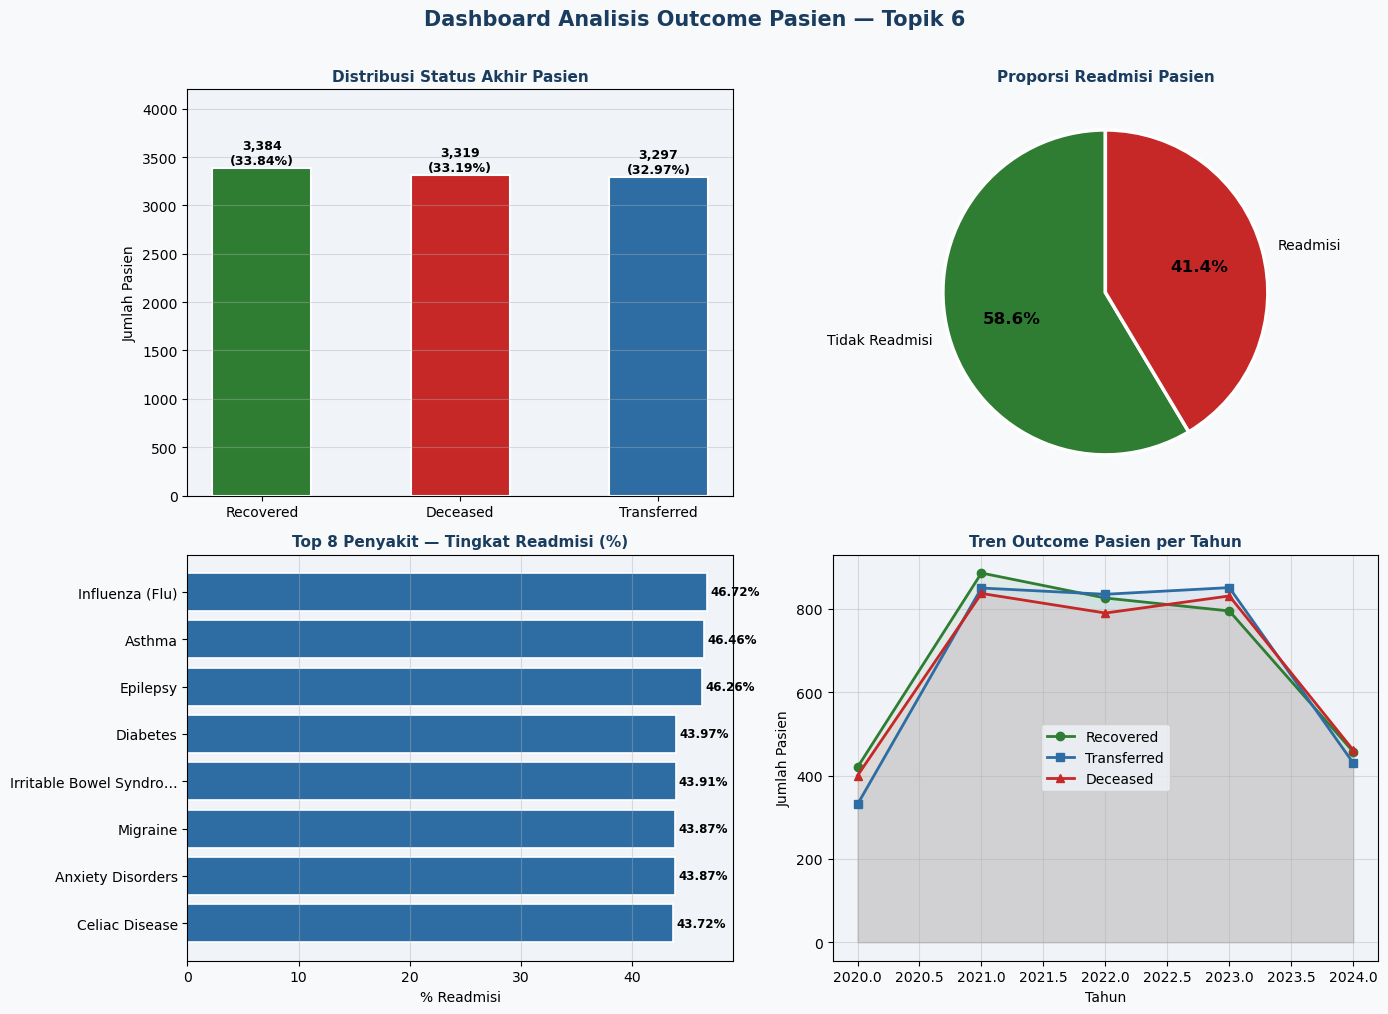

In [33]:
BLUE  = "#1A3C5E"
LBLUE = "#2E6DA4"
GREEN = "#2E7D32"
RED   = "#C62828"
GOLD  = "#C9A84C"
GREY  = "#F0F4F8"

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Dashboard Analisis Outcome Pasien — Topik 6",
             fontsize=15, fontweight="bold", color=BLUE, y=1.01)

# Distribusi discharge status 
ax = axes[0, 0]
colors_bar = [GREEN, RED, LBLUE]
bars = ax.bar(q1["status_akhir"], q1["jumlah_pasien"], color=colors_bar,
              edgecolor="white", linewidth=1.5, width=0.5)
for bar, val, pct in zip(bars, q1["jumlah_pasien"], q1["persentase"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+40,
            f"{val:,}\n({pct}%)", ha="center", fontsize=9, fontweight="bold")
ax.set_title("Distribusi Status Akhir Pasien", fontweight="bold", color=BLUE, fontsize=11)
ax.set_ylabel("Jumlah Pasien"); ax.set_ylim(0, 4200)
ax.grid(axis="y", alpha=0.4); ax.set_facecolor(GREY)

# Pie readmisi 
ax2 = axes[0, 1]
total = q1["jumlah_pasien"].sum()
readmisi    = q1["total_readmisi"].sum()
no_readmisi = total - readmisi
wedges, texts, autotexts = ax2.pie(
    [no_readmisi, readmisi], labels=["Tidak Readmisi", "Readmisi"],
    colors=[GREEN, RED], autopct="%1.1f%%", startangle=90,
    wedgeprops=dict(edgecolor="white", linewidth=2.5)
)
for at in autotexts: at.set_fontsize(12); at.set_fontweight("bold")
ax2.set_title("Proporsi Readmisi Pasien", fontweight="bold", color=BLUE, fontsize=11)

# Top 8 penyakit readmisi tertinggi 
ax3 = axes[1, 0]
top8 = q2.head(8).copy()
short = [n[:22]+"…" if len(n)>22 else n for n in top8["penyakit"]]
hbars = ax3.barh(short[::-1], top8["pct_readmisi"][::-1], color=LBLUE,
                 edgecolor="white", linewidth=1.2)
for bar, val in zip(hbars, top8["pct_readmisi"][::-1]):
    ax3.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
             f"{val}%", va="center", fontsize=8.5, fontweight="bold")
ax3.set_title("Top 8 Penyakit — Tingkat Readmisi (%)",
              fontweight="bold", color=BLUE, fontsize=11)
ax3.set_xlabel("% Readmisi"); ax3.grid(axis="x", alpha=0.4); ax3.set_facecolor(GREY)

# Tren outcome per tahun 
ax4 = axes[1, 1]
ax4.plot(q4["tahun"], q4["recovered"],   marker="o", color=GREEN, linewidth=2, label="Recovered")
ax4.plot(q4["tahun"], q4["transferred"], marker="s", color=LBLUE, linewidth=2, label="Transferred")
ax4.plot(q4["tahun"], q4["deceased"],    marker="^", color=RED,   linewidth=2, label="Deceased")
ax4.fill_between(q4["tahun"], q4["recovered"],   alpha=0.08, color=GREEN)
ax4.fill_between(q4["tahun"], q4["transferred"], alpha=0.08, color=LBLUE)
ax4.fill_between(q4["tahun"], q4["deceased"],    alpha=0.08, color=RED)
ax4.set_title("Tren Outcome Pasien per Tahun", fontweight="bold", color=BLUE, fontsize=11)
ax4.set_xlabel("Tahun"); ax4.set_ylabel("Jumlah Pasien")
ax4.legend(); ax4.grid(alpha=0.4); ax4.set_facecolor(GREY)

plt.tight_layout()
plt.savefig("dashboard_outcome_pasien.png", dpi=150, bbox_inches="tight")
plt.show()

**Visualisasi Outcome per Departemen Rujukan**

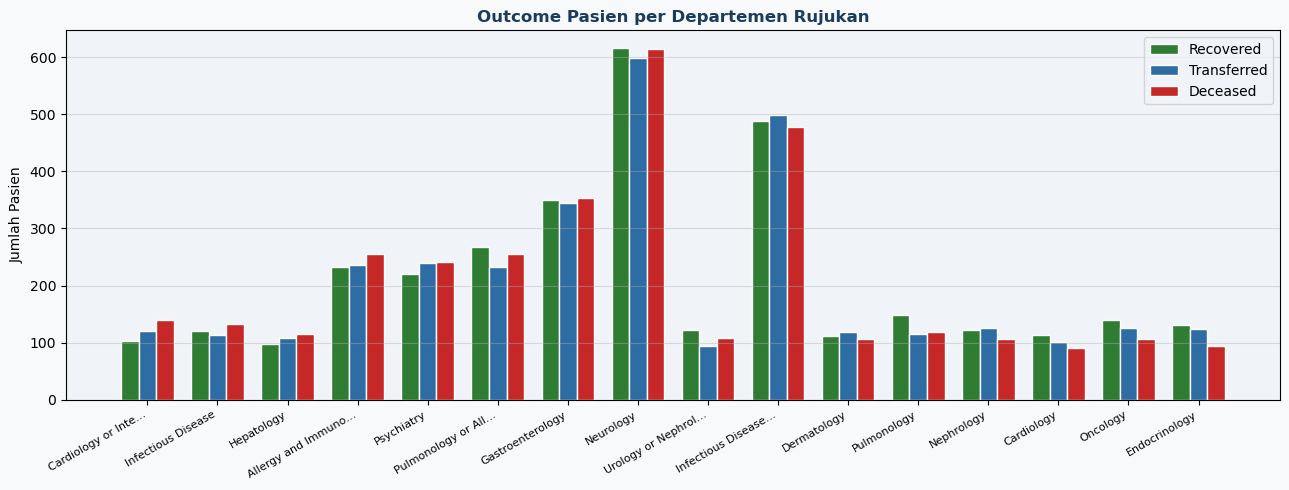

In [34]:
fig2, ax = plt.subplots(figsize=(13, 5))
ax.set_facecolor(GREY)

x = np.arange(len(q3["departemen"]))
w = 0.25
ax.bar(x - w, q3["recovered"],   w, label="Recovered",   color=GREEN, edgecolor="white")
ax.bar(x,     q3["transferred"], w, label="Transferred",  color=LBLUE, edgecolor="white")
ax.bar(x + w, q3["deceased"],    w, label="Deceased",     color=RED,   edgecolor="white")

short_dept = [d[:18]+"…" if len(d)>18 else d for d in q3["departemen"]]
ax.set_xticks(x)
ax.set_xticklabels(short_dept, rotation=30, ha="right", fontsize=8)
ax.set_title("Outcome Pasien per Departemen Rujukan", fontweight="bold", color=BLUE, fontsize=12)
ax.set_ylabel("Jumlah Pasien")
ax.legend(); ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.savefig("outcome_per_departemen.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
conn.close()